# Paso 2 · Exploración y análisis preliminar (Programación, Unidad 1)

| | |
|---|---|
| **IDs del enunciado** | P1.1 y P1.E1 (entorno y librerías), P1.2 (Pandas, NumPy, Matplotlib, Seaborn), P1.3 y P1.E2 (carga e inspección), P1.4 y P1.E3 (operaciones básicas), P1.5 y P1.E4 (visualizaciones), E3 (datos realistas del sector financiero) |
| **Fase** | F2 · Explorar (CRISP-DM: *Data Understanding*) |
| **Historia** | HU-02 · Sprint S6 (origen en S1) |
| **Entregable** | este notebook |

Estructura: **1. P1.1 Entorno · 2. P1.2 Librerías · 3. P1.3 Carga e inspección · 4. P1.4 Operaciones básicas
(pandas y SQL con DuckDB) · 5. P1.5 Visualizaciones · Conclusiones**. Los nulos, duplicados y valores
imposibles **solo se reportan** aquí; se tratan en el notebook 03.

**Aprendizaje de la unidad (Módulo 1 · Unidad 1).** Explorar es preguntarle a los datos antes de
modelarlos. En lo conceptual: distinguir tipos de variable, leer distribuciones (asimetría, valores
imposibles, desbalance de clases) y separar lo que *describe* a la población de lo que *discrimina* entre
pagadores e impagos. En lo práctico: inspeccionar un `DataFrame` (`shape`, `info`, `describe`, `nunique`),
seleccionar, filtrar, ordenar y agregar con pandas, comprobar que cada operación tiene su equivalente
exacto en **SQL con DuckDB** (motor analítico en proceso) y construir gráficos con título, ejes e
interpretación.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


## 1. P1.1 · Entorno

`setup()` (de `credit_risk.notebook`) fija la semilla, silencia avisos, aplica el estilo visual del proyecto
y devuelve el entorno con las versiones de las librerías.

- **Jupyter local:** desde `Back/`, crear el entorno (`python -m venv .venv`), instalar el paquete en modo
  editable (`pip install -e .`), registrar el kernel `credit-risk` y abrir este notebook con
  *Restart & Run All*.
- **Google Colab:** antes de esta celda, instalar el paquete desde el repositorio
  (`!git clone <URL_DEL_REPOSITORIO> proyecto && pip install -e proyecto/Back`); si el clon no trae el CSV,
  la celda siguiente pide subirlo (`files.upload()`) o se puede montar Drive (`drive.mount('/content/drive')`)
  y pasar la ruta a `cargar_datos(ruta)`.

In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
from credit_risk import config
from credit_risk.notebook import en_colab, ruta

RUTA_CSV = None  # None = config.RAW_DATA_PATH (repositorio clonado o Jupyter local)
if en_colab():
    # Colab: el paquete ya se instaló desde el repositorio (ver la celda anterior).
    if not config.RAW_DATA_PATH.exists():
        from google.colab import files  # noqa: F401  (solo existe en Colab)

        RUTA_CSV = next(iter(files.upload()))  # seleccionar credit_risk.csv
    print("Entorno: Google Colab")
else:
    print("Entorno: Jupyter local (kernel credit-risk)")
print(f"Datos: {ruta(RUTA_CSV or config.RAW_DATA_PATH)} · semilla: {config.RANDOM_STATE}")

Entorno: Jupyter local (kernel credit-risk)
Datos: db/credit_risk.csv · semilla: 42


## 2. P1.2 · Librerías y configuración

Las cuatro librerías del enunciado (`pandas as pd`, `numpy as np`, `matplotlib.pyplot as plt`,
`seaborn as sns`) más **DuckDB** para las consultas SQL en proceso (ADR-007). El estilo de los gráficos lo
aplica `setup()` (`credit_risk.reporting.aplicar_estilo`); aquí se ajusta la presentación de las tablas.

In [5]:
import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.cbook import boxplot_stats

from credit_risk.data import cargar_datos
from credit_risk.reporting import PALETA, figura_front

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_colwidth = 40
TARGET, ID_COL, TEXT_COL = config.TARGET, config.ID_COL, config.TEXT_COL
COLORES_CLASE = {0: PALETA["pago"], 1: PALETA["impago"]}
NOMBRE_CLASE = {0: "Pagó (0)", 1: "Impago (1)"}
configuracion = {
    "pandas.display.float_format": "{:,.2f}", "pandas.display.max_columns": pd.options.display.max_columns,
    "pandas.display.max_colwidth": pd.options.display.max_colwidth,
    "matplotlib.figure.facecolor": matplotlib.rcParams["figure.facecolor"],
    "matplotlib.axes.prop_cycle (3 primeros)": ", ".join(matplotlib.rcParams["axes.prop_cycle"].by_key()["color"][:3]),
    "seaborn": sns.__version__, "duckdb": duckdb.__version__,
}
pd.Series(configuracion, name="valor").to_frame()

,valor
pandas.display.float_format,"{:,.2f}"
pandas.display.max_columns,40
pandas.display.max_colwidth,40
matplotlib.figure.facecolor,#0E0F13
matplotlib.axes.prop_cycle (3 primeros),"#505CFD, #F97316, #34D399"
seaborn,0.13.2
duckdb,1.5.6


## 3. P1.3 · Carga e inspección del dataset

Se lee el CSV crudo con `credit_risk.data.cargar_datos()` (ruta de `config.RAW_DATA_PATH`).

In [6]:
df = cargar_datos(RUTA_CSV)
if FAST:
    df = df.sample(3000, random_state=config.RANDOM_STATE).reset_index(drop=True)
print(f"Dimensiones (filas, columnas): {df.shape}")
df.head()

Dimensiones (filas, columnas): (12144, 21)


,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
0,CLI_006413,23,M,Union_libre,Tecnico,Pensionado,5.00,4,Arriendo,"1,840,000.00","10,634,000.00",12,34.10,Consolidacion_deuda,0,1,0.56,805.00,0.28,Quisiera acceder a financiacion para...,0
1,CLI_008728,79,F,Casado,Secundaria,Empleado,56.80,3,Propia,"3,954,000.00","14,842,000.00",24,13.80,Libre_inversion,4,0,0.47,738.00,0.56,Necesito el prestamo para una invers...,0
2,CLI_002268,63,F,Union_libre,Primaria,Independiente,7.00,3,Propia,"1,187,000.00","3,943,000.00",6,14.20,Libre_inversion,2,0,0.52,779.00,0.75,Requiero el prestamo para cubrir gas...,0
3,CLI_008456,29,F,Soltero,Secundaria,Empleado,0.20,0,Arriendo,"1,181,000.00","7,418,000.00",48,41.20,Negocio,1,2,0.47,639.00,0.55,Pido este credito con el fin de capi...,1
4,CLI_010961,65,M,Soltero,Secundaria,Empleado,NaN,1,Arriendo,"2,303,000.00","9,208,000.00",24,15.30,Libre_inversion,2,0,0.27,752.00,0.32,Solicito este credito para un proyec...,0


In [7]:
df.tail()

,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
12139,CLI_011965,33,F,Casado,Universitario,Empleado,5.40,0,NaN,"3,048,000.00","78,878,000.00",36,25.40,Vivienda,2,0,1.50,703.00,0.23,Solicito este credito para hacer mej...,0
12140,CLI_005192,75,F,Soltero,Tecnico,Empleado,NaN,2,Arriendo,"3,393,000.00","6,904,000.00",36,33.00,Libre_inversion,1,0,0.06,766.00,0.06,Solicito este credito para gastos va...,0
12141,CLI_005391,29,F,Casado,Secundaria,Empleado,7.30,3,Propia,"4,159,000.00","23,374,000.00",24,34.50,Consolidacion_deuda,0,0,0.41,836.00,0.00,Requiero el prestamo para reorganiza...,0
12142,CLI_000861,78,F,Casado,Primaria,Empleado,40.30,0,Arriendo,"1,534,000.00","9,563,000.00",60,11.50,Vehiculo,0,0,0.48,710.00,0.36,Necesito el prestamo para adquirir u...,0
12143,CLI_007271,37,F,Viudo,Secundaria,Empleado,8.90,4,Propia,"2,899,000.00","5,234,000.00",36,41.40,Libre_inversion,1,0,0.37,690.00,0.45,Pido este credito con el fin de gast...,1


In [8]:
df.sample(5, random_state=config.RANDOM_STATE)

,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
6412,CLI_001244,48,M,Union_libre,Secundaria,Empleado,3.40,3,Propia,"2,144,000.00","13,232,000.00",12,15.20,Vehiculo,2,0,0.24,835.00,0.30,Pido este credito con el fin de adqu...,0
8727,CLI_001402,33,F,Divorciado,Primaria,Independiente,8.00,0,Arriendo,"2,001,000.00","64,039,000.00",24,12.40,Vivienda,3,1,1.50,685.00,0.57,Pido este credito con el fin de remo...,0
2267,CLI_004194,20,F,Soltero,Universitario,Independiente,1.80,1,Arriendo,"2,906,000.00","27,756,000.00",48,34.90,Negocio,2,0,0.87,799.00,0.60,Necesito el prestamo para capital de...,1
8455,CLI_003172,77,M,Union_libre,Primaria,Empleado,16.90,1,Arriendo,"1,490,000.00","6,689,000.00",36,12.00,Libre_inversion,0,0,0.24,950.00,0.14,Requiero el prestamo para gastos var...,0
10960,CLI_005960,73,F,Soltero,Universitario,Empleado,17.70,0,Propia,"3,376,000.00","13,844,000.00",48,32.80,Consolidacion_deuda,1,0,0.52,849.00,0.11,Pido este credito con el fin de unif...,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12144 entries, 0 to 12143
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_cliente                12144 non-null  object 
 1   edad                      12144 non-null  int64  
 2   sexo                      12144 non-null  object 
 3   estado_civil              12144 non-null  object 
 4   nivel_educativo           12144 non-null  object 
 5   situacion_laboral         11650 non-null  object 
 6   antiguedad_laboral_anios  11026 non-null  float64
 7   personas_a_cargo          12144 non-null  int64  
 8   tipo_vivienda             11757 non-null  object 
 9   ingreso_mensual           11395 non-null  float64
 10  monto_credito             12144 non-null  float64
 11  plazo_meses               12144 non-null  int64  
 12  tasa_interes_anual        12144 non-null  float64
 13  proposito                 12144 non-null  object 
 14  num_cr

In [10]:
tipos = df.dtypes.astype(str)
pd.DataFrame({"n_columnas": tipos.value_counts(),
              "columnas": tipos.groupby(tipos).apply(lambda s: ", ".join(s.index))})

,n_columnas,columnas
float64,7,"antiguedad_laboral_anios, ingreso_me..."
int64,6,"edad, personas_a_cargo, plazo_meses,..."
object,8,"id_cliente, sexo, estado_civil, nive..."


In [11]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
edad,"12,144.00",49.13,23.65,1.00,33.00,49.00,65.00,999.00
antiguedad_laboral_anios,"11,026.00",13.16,13.20,0.00,2.50,8.90,20.00,62.00
personas_a_cargo,"12,144.00",1.61,1.55,0.00,0.00,1.00,2.00,6.00
ingreso_mensual,"11,395.00","2,624,177.10","2,035,883.68","312,000.00","1,529,500.00","2,237,000.00","3,203,000.00","64,540,000.00"
monto_credito,"12,144.00","21,541,744.24","31,447,367.71","1,000,000.00","6,986,000.00","12,281,000.00","23,411,000.00","1,033,300,000.00"
plazo_meses,"12,144.00",32.57,19.55,6.00,18.00,24.00,48.00,84.00
tasa_interes_anual,"12,144.00",26.12,9.24,10.00,18.10,26.20,34.10,42.00
num_creditos_activos,"12,144.00",1.58,1.26,0.00,1.00,1.00,2.00,8.00
moras_ultimos_12m,"12,144.00",0.51,0.91,0.00,0.00,0.00,1.00,10.00
relacion_deuda_ingreso,"11,532.00",0.62,0.38,0.00,0.36,0.55,0.79,1.50


In [12]:
# Estadísticas descriptivas de las variables categóricas y de texto
df.describe(include="object").T

,count,unique,top,freq
id_cliente,12144,12000,CLI_004706,2
sexo,12144,2,M,6273
estado_civil,12144,5,Soltero,4569
nivel_educativo,12144,5,Secundaria,3551
situacion_laboral,11650,4,Empleado,6427
tipo_vivienda,11757,3,Arriendo,4969
proposito,12144,6,Libre_inversion,3430
texto_solicitud,11904,4453,Necesito el prestamo para un proyect...,20


In [13]:
# Valores únicos por columna
df.nunique().sort_values().rename("valores_unicos").to_frame().T

,default,sexo,tipo_vivienda,situacion_laboral,estado_civil,nivel_educativo,proposito,personas_a_cargo,plazo_meses,num_creditos_activos,moras_ultimos_12m,edad,tasa_interes_anual,antiguedad_laboral_anios,puntaje_buro,uso_cupo_tarjetas,relacion_deuda_ingreso,ingreso_mensual,texto_solicitud,monto_credito,id_cliente
valores_unicos,2,2,3,4,5,5,6,7,9,9,11,68,321,580,616,992,1394,4277,4453,10082,12000


In [14]:
# Valores nulos (solo se reportan; se tratan en el notebook 03)
nulos = pd.DataFrame({"nulos": df.isna().sum(), "pct": df.isna().mean() * 100})
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
print(f"Columnas con nulos: {len(nulos)} · celdas nulas: {int(df.isna().sum().sum()):,}")
nulos

Columnas con nulos: 7 · celdas nulas: 4,088


,nulos,pct
antiguedad_laboral_anios,1118,9.21
ingreso_mensual,749,6.17
relacion_deuda_ingreso,612,5.04
situacion_laboral,494,4.07
puntaje_buro,488,4.02
tipo_vivienda,387,3.19
texto_solicitud,240,1.98


In [15]:
# Duplicados y valores imposibles (solo se reportan)
dup_exactos = int(df.duplicated().sum())
dup_id = int(df[ID_COL].duplicated().sum())
edad_invalida = ~df["edad"].between(*config.EDAD_VALIDA)
print(f"Filas duplicadas exactas : {dup_exactos} ({dup_exactos / len(df):.2%})")
print(f"IDs repetidos            : {dup_id}")
print(f"Edades fuera de {config.EDAD_VALIDA[0]}-{config.EDAD_VALIDA[1]}  : {int(edad_invalida.sum())} "
      f"-> valores {sorted(df.loc[edad_invalida, 'edad'].unique().tolist())}")
print(f"Montos o ingresos <= 0   : {int((df['monto_credito'] <= 0).sum())} / {int((df['ingreso_mensual'] <= 0).sum())}")

Filas duplicadas exactas : 144 (1.19%)
IDs repetidos            : 144
Edades fuera de 18-100  : 25 -> valores [1, 2, 120, 150, 999]
Montos o ingresos <= 0   : 0 / 0


In [16]:
# Distribución de la variable objetivo
dist = pd.DataFrame({"clientes": df[TARGET].value_counts(), "proporcion": df[TARGET].value_counts(normalize=True)})
dist.index = dist.index.map(NOMBRE_CLASE)
print(f"Tasa de default: {df[TARGET].mean():.2%}")
dist

Tasa de default: 35.63%


,clientes,proporcion
default,,
Pagó (0),7817,0.64
Impago (1),4327,0.36


**Lectura.** El archivo tiene **12.144 filas y 21 columnas**: 13 numéricas (7 `float64` y 6 `int64`,
incluido el objetivo) y 8 de tipo texto (`id_cliente`, las 6 categóricas y `texto_solicitud`). Problemas de
calidad que se tratarán en el notebook 03: **7 columnas con nulos** (de 9,21 % en `antiguedad_laboral_anios`
a 1,98 % en `texto_solicitud`; 4.088 celdas en total), **144 filas duplicadas exactas** y 144 IDs repetidos
(hay 12.000 IDs únicos), y **25 edades imposibles** (1, 2, 120, 150 y 999). No hay montos ni ingresos
menores o iguales a cero, pero los máximos son errores evidentes de digitación: el monto llega a
1.033.300.000 COP con una mediana de 12.281.000, y el ingreso a 64.540.000 con una mediana de 2.237.000. El
texto libre solo tiene 4.453 valores distintos. La clase impago es el **35,63 %** (4.327 de 12.144): un
desbalance moderado que justifica estratificar la partición train/test.

## 4. P1.4 · Operaciones básicas en pandas y su equivalente SQL (DuckDB)

Cada operación se hace primero en pandas y luego con `duckdb.sql(...)` **directamente sobre el
`DataFrame` `df`** (DuckDB lo lee en memoria, sin copiarlo a una base). La función `coinciden` comprueba
con `pandas.testing.assert_frame_equal` que ambas tablas son iguales en orden y valores.
Nota: `default` es palabra reservada en SQL, por eso va entre comillas dobles.

In [17]:
def coinciden(a: pd.DataFrame, b: pd.DataFrame) -> None:
    """Falla si pandas y DuckDB no devuelven la misma tabla (mismas columnas, orden y valores)."""
    a, b = a.reset_index(drop=True), b.reset_index(drop=True)
    pd.testing.assert_frame_equal(a, b, check_dtype=False, check_exact=False, rtol=1e-9)
    print(f"✔ pandas y DuckDB coinciden: {a.shape[0]:,} filas × {a.shape[1]} columnas")

### 4.1 Selección

**Por nombre de columna.**

In [18]:
sel_pd = df[[ID_COL, "edad", "ingreso_mensual", "monto_credito", TARGET]].head(5)
sel_sql = duckdb.sql('SELECT id_cliente, edad, ingreso_mensual, monto_credito, "default" FROM df LIMIT 5').df()
coinciden(sel_pd, sel_sql)
sel_sql

✔ pandas y DuckDB coinciden: 5 filas × 5 columnas


,id_cliente,edad,ingreso_mensual,monto_credito,default
0,CLI_006413,23,"1,840,000.00","10,634,000.00",0
1,CLI_008728,79,"3,954,000.00","14,842,000.00",0
2,CLI_002268,63,"1,187,000.00","3,943,000.00",0
3,CLI_008456,29,"1,181,000.00","7,418,000.00",1
4,CLI_010961,65,"2,303,000.00","9,208,000.00",0


**Por tipo de dato** (`select_dtypes`). En SQL, `DESCRIBE` expone el tipo de cada columna y se filtra
como cualquier tabla.

In [19]:
num_pd = df.select_dtypes(include="number").columns.tolist()
cat_pd = df.select_dtypes(include="object").columns.drop([ID_COL, TEXT_COL]).tolist()
tipos_sql = duckdb.sql("SELECT column_name, column_type FROM (DESCRIBE SELECT * FROM df)").df()
num_sql = tipos_sql.query("column_type in ['BIGINT', 'DOUBLE']")["column_name"].tolist()
assert num_pd == num_sql
print(f"✔ {len(num_pd)} numéricas iguales en pandas y DuckDB: {', '.join(num_pd)}")
print(f"Categóricas ({len(cat_pd)}): {', '.join(cat_pd)}")
tipos_sql.groupby("column_type")["column_name"].agg(n="size", columnas=", ".join)

✔ 13 numéricas iguales en pandas y DuckDB: edad, antiguedad_laboral_anios, personas_a_cargo, ingreso_mensual, monto_credito, plazo_meses, tasa_interes_anual, num_creditos_activos, moras_ultimos_12m, relacion_deuda_ingreso, puntaje_buro, uso_cupo_tarjetas, default
Categóricas (6): sexo, estado_civil, nivel_educativo, situacion_laboral, tipo_vivienda, proposito


,n,columnas
column_type,,
BIGINT,6,"edad, personas_a_cargo, plazo_meses,..."
DOUBLE,7,"antiguedad_laboral_anios, ingreso_me..."
VARCHAR,8,"id_cliente, sexo, estado_civil, nive..."


**`loc` (etiquetas) e `iloc` (posiciones).** El equivalente de `iloc[10:15]` en SQL es `LIMIT 5 OFFSET 10`
(DuckDB conserva el orden de inserción del `DataFrame`).

In [20]:
display(df.loc[df.index[:3], ["edad", "proposito", TARGET]])
iloc_pd = df.iloc[10:15, [1, 9, 10, -1]]
iloc_sql = duckdb.sql('SELECT edad, ingreso_mensual, monto_credito, "default" FROM df LIMIT 5 OFFSET 10').df()
coinciden(iloc_pd, iloc_sql)
iloc_sql

,edad,proposito,default
0,23,Consolidacion_deuda,0
1,79,Libre_inversion,0
2,63,Libre_inversion,0


✔ pandas y DuckDB coinciden: 5 filas × 4 columnas


,edad,ingreso_mensual,monto_credito,default
0,38,"7,220,000.00","87,296,000.00",0
1,23,"1,450,000.00","12,355,000.00",0
2,71,"3,277,000.00","19,901,000.00",1
3,21,"2,080,000.00","13,907,000.00",1
4,44,"3,923,000.00","14,771,000.00",0


### 4.2 Filtrado

**Condición simple:** clientes con al menos una mora en los últimos 12 meses.

In [21]:
con_moras = df[df["moras_ultimos_12m"] > 0]
f1_pd = pd.DataFrame({"clientes": [len(con_moras)], "tasa_default": [con_moras[TARGET].mean()]})
f1_sql = duckdb.sql('SELECT COUNT(*) AS clientes, AVG("default") AS tasa_default FROM df '
                    "WHERE moras_ultimos_12m > 0").df()
coinciden(f1_pd, f1_sql)
print(f"Tasa global de default: {df[TARGET].mean():.2%}")
f1_sql

✔ pandas y DuckDB coinciden: 1 filas × 2 columnas
Tasa global de default: 35.63%


,clientes,tasa_default
0,4074,0.60


**Condición compuesta:** ingreso bajo (< percentil 25) **y** monto alto (> percentil 75). En SQL los
percentiles se calculan con `quantile_cont`, la misma interpolación lineal que usa pandas.

In [22]:
p25_ing, p75_monto = df["ingreso_mensual"].quantile(0.25), df["monto_credito"].quantile(0.75)
riesgo = df[(df["ingreso_mensual"] < p25_ing) & (df["monto_credito"] > p75_monto)]
f2_pd = pd.DataFrame({"p25_ingreso": [p25_ing], "p75_monto": [p75_monto], "clientes": [len(riesgo)],
                      "tasa_default": [riesgo[TARGET].mean()]})
f2_sql = duckdb.sql("""
    WITH q AS (SELECT quantile_cont(ingreso_mensual, 0.25) AS p25_ingreso,
                      quantile_cont(monto_credito, 0.75) AS p75_monto FROM df)
    SELECT ANY_VALUE(p25_ingreso) AS p25_ingreso, ANY_VALUE(p75_monto) AS p75_monto,
           COUNT(*) AS clientes, AVG("default") AS tasa_default
    FROM df, q WHERE ingreso_mensual < p25_ingreso AND monto_credito > p75_monto
""").df()
coinciden(f2_pd, f2_sql)
f2_sql

✔ pandas y DuckDB coinciden: 1 filas × 4 columnas

,p25_ingreso,p75_monto,clientes,tasa_default
0,"1,529,500.00","23,411,000.00",263,0.43


**`query()`:** puntaje de buró bajo y uso alto del cupo de tarjetas. Se comparan **todas** las filas filtradas.

In [23]:
q_pd = df.query("puntaje_buro < 600 and uso_cupo_tarjetas > 0.7")[["edad", "puntaje_buro", "uso_cupo_tarjetas", TARGET]]
q_sql = duckdb.sql('SELECT edad, puntaje_buro, uso_cupo_tarjetas, "default" FROM df '
                   "WHERE puntaje_buro < 600 AND uso_cupo_tarjetas > 0.7").df()
coinciden(q_pd, q_sql)
print(f"query -> {len(q_pd):,} clientes · tasa de default {q_pd[TARGET].mean():.2%}")
q_sql.head()

✔ pandas y DuckDB coinciden: 1,177 filas × 4 columnas
query -> 1,177 clientes · tasa de default 87.68%


,edad,puntaje_buro,uso_cupo_tarjetas,default
0,49,545.00,0.72,1
1,48,471.00,1.00,1
2,22,598.00,0.70,1
3,38,564.00,0.72,1
4,39,548.00,0.74,1


### 4.3 Ordenamiento

**Por una columna:** los 5 créditos de mayor monto (candidatos a error de digitación).

In [24]:
cols_orden = [ID_COL, "ingreso_mensual", "monto_credito", TARGET]
o1_pd = df.sort_values("monto_credito", ascending=False)[cols_orden].head(5)
o1_sql = duckdb.sql('SELECT id_cliente, ingreso_mensual, monto_credito, "default" FROM df '
                    "ORDER BY monto_credito DESC LIMIT 5").df()
coinciden(o1_pd, o1_sql)
o1_sql

✔ pandas y DuckDB coinciden: 5 filas × 4 columnas


,id_cliente,ingreso_mensual,monto_credito,default
0,CLI_008419,"5,925,000.00","1,033,300,000.00",0
1,CLI_011363,"4,709,000.00","914,640,000.00",1
2,CLI_009476,"3,847,000.00","717,650,000.00",0
3,CLI_003849,"2,527,000.00","563,340,000.00",1
4,CLI_007988,"4,031,000.00","524,450,000.00",1


**Por varias columnas:** más moras primero y, a igualdad, menor puntaje de buró (el `id_cliente` desempata
para que el orden sea determinista en ambos motores).

In [25]:
o2_pd = (df.sort_values(["moras_ultimos_12m", "puntaje_buro", ID_COL], ascending=[False, True, True])
         [[ID_COL, "moras_ultimos_12m", "puntaje_buro", TARGET]].head(5))
o2_sql = duckdb.sql('SELECT id_cliente, moras_ultimos_12m, puntaje_buro, "default" FROM df '
                    "ORDER BY moras_ultimos_12m DESC, puntaje_buro ASC, id_cliente ASC LIMIT 5").df()
coinciden(o2_pd, o2_sql)
o2_sql

✔ pandas y DuckDB coinciden: 5 filas × 4 columnas

,id_cliente,moras_ultimos_12m,puntaje_buro,default
0,CLI_011326,10,150.00,1
1,CLI_004637,9,237.00,1
2,CLI_002775,9,276.00,1
3,CLI_006742,9,278.00,1
4,CLI_009220,9,286.00,1


### 4.4 Agregaciones

**`groupby` + `agg`:** tasa de impago por situación laboral (pandas excluye el grupo nulo por defecto; en
SQL se excluye con `IS NOT NULL`).

In [26]:
agg_pd = (df.groupby("situacion_laboral")
          .agg(clientes=(TARGET, "size"), tasa_default=(TARGET, "mean"),
               ingreso_mediano=("ingreso_mensual", "median"), puntaje_medio=("puntaje_buro", "mean"))
          .sort_values("tasa_default", ascending=False).reset_index())
agg_sql = duckdb.sql("""
    SELECT situacion_laboral, COUNT(*) AS clientes, AVG("default") AS tasa_default,
           MEDIAN(ingreso_mensual) AS ingreso_mediano, AVG(puntaje_buro) AS puntaje_medio
    FROM df WHERE situacion_laboral IS NOT NULL
    GROUP BY situacion_laboral ORDER BY tasa_default DESC
""").df()
coinciden(agg_pd, agg_sql)
agg_sql

✔ pandas y DuckDB coinciden: 4 filas × 5 columnas


,situacion_laboral,clientes,tasa_default,ingreso_mediano,puntaje_medio
0,Desempleado,813,0.62,"1,005,000.00",605.34
1,Independiente,3295,0.39,"2,326,000.00",693.70
2,Empleado,6427,0.33,"2,347,000.00",721.16
3,Pensionado,1115,0.24,"2,300,000.00",755.15


**`pivot_table`:** tasa de impago por nivel educativo (filas) y tipo de vivienda (columnas). DuckDB tiene
la sentencia `PIVOT`; el orden ordinal de la educación se impone con `list_position`.

In [27]:
orden_edu = config.CATEGORIAS["nivel_educativo"]
piv_pd = (pd.pivot_table(df, values=TARGET, index="nivel_educativo", columns="tipo_vivienda", aggfunc="mean")
          .reindex(orden_edu).rename_axis(columns=None).reset_index())
piv_sql = duckdb.sql(f"""
    SELECT * FROM (
        PIVOT (SELECT nivel_educativo, tipo_vivienda, "default" FROM df WHERE tipo_vivienda IS NOT NULL)
        ON tipo_vivienda USING AVG("default") GROUP BY nivel_educativo
    ) ORDER BY list_position({orden_edu}, nivel_educativo)
""").df()
coinciden(piv_pd, piv_sql)
piv_sql

✔ pandas y DuckDB coinciden: 5 filas × 4 columnas


,nivel_educativo,Arriendo,Familiar,Propia
0,Primaria,0.51,0.46,0.37
1,Secundaria,0.44,0.43,0.33
2,Tecnico,0.40,0.37,0.30
3,Universitario,0.35,0.32,0.26
4,Posgrado,0.28,0.24,0.26


**`value_counts(normalize=True)`:** composición de la cartera por propósito del crédito. En SQL, la
proporción es el conteo del grupo sobre el total (función de ventana `SUM(COUNT(*)) OVER ()`).

In [28]:
vc_pd = df["proposito"].value_counts(normalize=True).rename("proporcion").reset_index()
vc_sql = duckdb.sql("SELECT proposito, COUNT(*) / SUM(COUNT(*)) OVER () AS proporcion FROM df "
                    "GROUP BY proposito ORDER BY proporcion DESC").df()
coinciden(vc_pd, vc_sql)
vc_sql

✔ pandas y DuckDB coinciden: 6 filas × 2 columnas


,proposito,proporcion
0,Libre_inversion,0.28
1,Vehiculo,0.17
2,Consolidacion_deuda,0.16
3,Vivienda,0.14
4,Negocio,0.14
5,Educacion,0.10


**Lectura.** Las **11 comparaciones** pandas ↔ DuckDB coinciden en orden y valores: SQL en proceso es una
forma equivalente (y a menudo más legible) de hacer las mismas operaciones. El filtrado ya muestra señales
fuertes: con al menos una mora el impago sube a **59,7 %** (4.074 clientes) frente al 35,63 % global, y con
buró < 600 y uso del cupo > 0,7 llega a **87,7 %** (1.177 clientes); la combinación ingreso bajo y monto alto
lo eleva mucho menos (43 %, 263 clientes). Por situación laboral, los desempleados (62 %) e independientes
(39 %) superan a empleados (33 %) y pensionados (24 %); los desempleados tienen además el menor ingreso
mediano (1.005.000 COP) y el menor buró medio (605). En la tabla dinámica la tasa baja con el nivel educativo
en los tres tipos de vivienda y, a igual educación, la vivienda propia tiene la menor tasa salvo en Posgrado
(Familiar 0,24 frente a Propia 0,26). Libre inversión es el propósito más frecuente (28 % de la cartera).

## 5. P1.5 · Visualizaciones exploratorias

Para que los errores de digitación no aplasten los ejes, ingreso y monto se muestran hasta su
**percentil 99** y la edad dentro del rango válido (`config.EDAD_VALIDA`); los atípicos se tratan en los
notebooks 03 y 04.

### 5.1 Histogramas de las variables numéricas clave

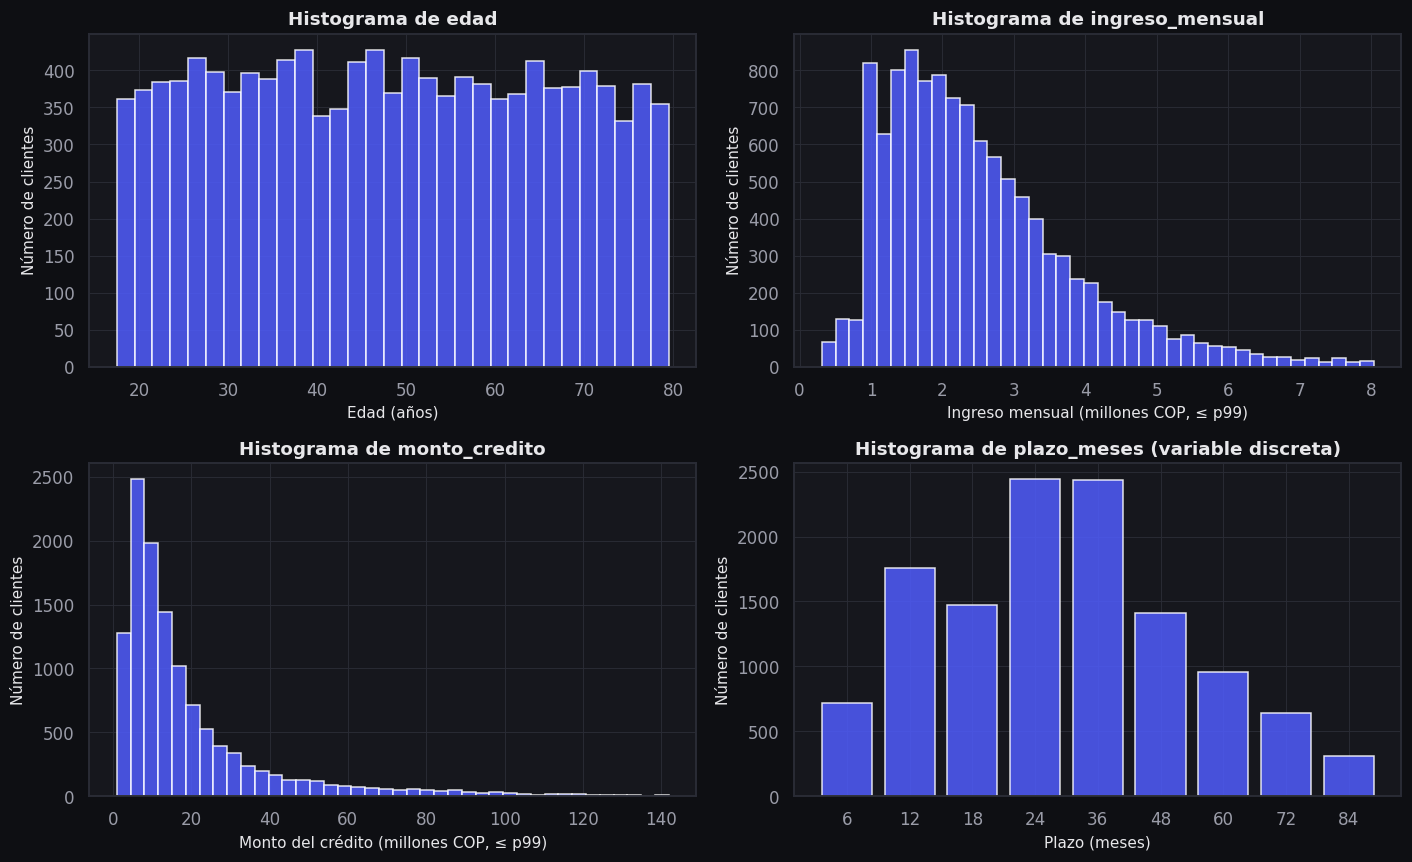

,media,mediana,asimetria
edad,48.83,49.00,0.02
ingreso_mensual,2.51,2.23,1.19
monto_credito,19.59,12.15,2.56
plazo_meses,32.57,24.00,0.79


In [29]:
def hasta_p99(s: pd.Series) -> pd.Series:
    s = s.dropna()
    return s[s <= s.quantile(0.99)]


specs = [("edad", df["edad"][df["edad"].between(*config.EDAD_VALIDA)], "Edad (años)", "edad"),
         ("ingreso_mensual", hasta_p99(df["ingreso_mensual"]) / 1e6, "Ingreso mensual (millones COP, ≤ p99)", "ingreso"),
         ("monto_credito", hasta_p99(df["monto_credito"]) / 1e6, "Monto del crédito (millones COP, ≤ p99)", "monto")]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, serie, xlabel, clave) in zip(axes.ravel(), specs):
    # edad es entera: cajas de 2 años alineadas a los enteros (40 cajas arbitrarias crean un patrón de sierra)
    bins = np.arange(serie.min() - 0.5, serie.max() + 1.5, 2) if col == "edad" else 40
    conteos, bordes = np.histogram(serie, bins=bins)
    ax.hist(serie, bins=bordes, color=PALETA["acento"], alpha=0.85)
    ax.set(title=f"Histograma de {col}", xlabel=xlabel, ylabel="Número de clientes")
    figura_front("histograma", f"Histograma de {col}",
                 {"bordes": bordes.round(4).tolist(), "series": [{"nombre": "Clientes", "conteos": conteos.tolist()}]},
                 ejes={"x": xlabel, "y": "Número de clientes"}, clave=f"hist_{clave}", opciones={"formato_y": "num"})
plazos = df["plazo_meses"].value_counts().sort_index()
ax = axes[1, 1]
ax.bar(plazos.index.astype(str), plazos.values, color=PALETA["acento"], alpha=0.85)
ax.set(title="Histograma de plazo_meses (variable discreta)", xlabel="Plazo (meses)", ylabel="Número de clientes")
plt.show()
figura_front("barras", "Histograma de plazo_meses (variable discreta)",
             {"categorias": plazos.index.astype(str).tolist(), "series": [{"nombre": "Clientes", "valores": plazos.tolist()}]},
             ejes={"x": "Plazo (meses)", "y": "Número de clientes"}, clave="hist_plazo", opciones={"formato_y": "num"})
pd.DataFrame({col: {"media": s.mean(), "mediana": s.median(), "asimetria": s.skew()} for col, s, *_ in specs}
             | {"plazo_meses": {"media": df["plazo_meses"].mean(), "mediana": df["plazo_meses"].median(),
                                "asimetria": df["plazo_meses"].skew()}}).T

**Interpretación.** La **edad** válida se reparte de forma casi uniforme entre 18 y 80 años (media 48,8,
mediana 49 y asimetría 0,02). **Ingreso** y **monto** tienen asimetría positiva (1,19 y 2,56): la media
supera a la mediana (2,51 frente a 2,23 millones en ingreso; 19,6 frente a 12,2 millones en monto) por una
cola larga a la derecha, típica de las variables monetarias, que pide escala logarítmica o *capping* (paso 4).
El **plazo** es discreto, con 9 valores entre 6 y 84 meses; 24 y 36 meses son los más frecuentes.

### 5.2 Histogramas por clase de las variables de buró y endeudamiento

Densidad (área = 1 en cada clase) para comparar formas aunque haya más pagadores que impagos.

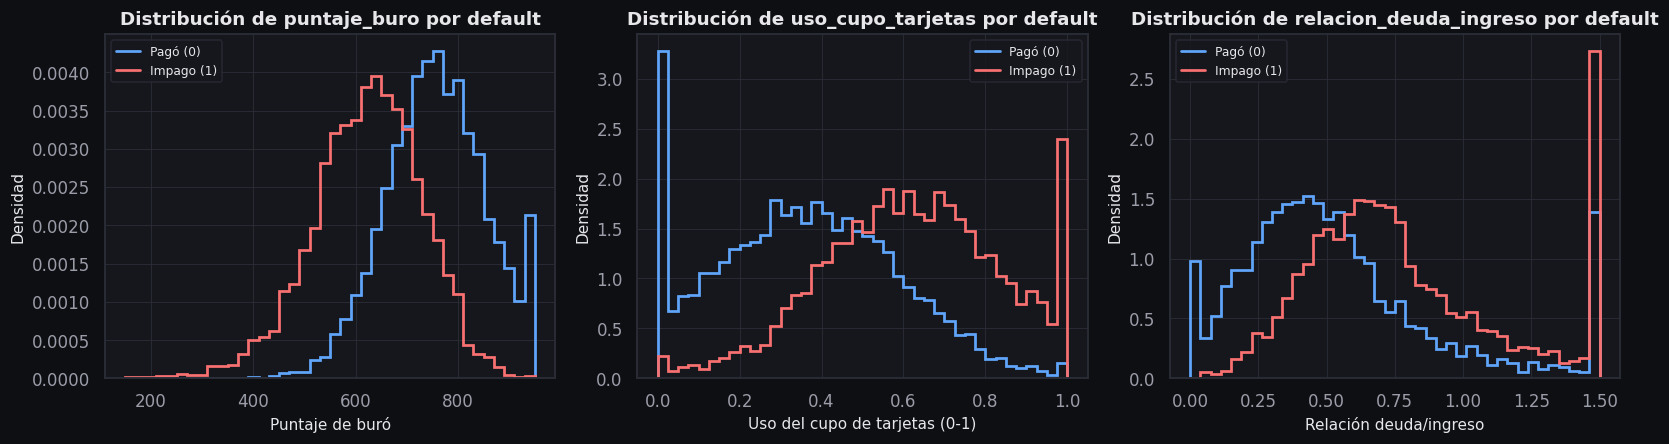

,puntaje_buro,uso_cupo_tarjetas,relacion_deuda_ingreso
mediana por clase,,,
Pagó (0),756.00,0.36,0.47
Impago (1),628.00,0.62,0.70


In [30]:
vars_buro = [("puntaje_buro", "Puntaje de buró"), ("uso_cupo_tarjetas", "Uso del cupo de tarjetas (0-1)"),
             ("relacion_deuda_ingreso", "Relación deuda/ingreso")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, xl) in zip(axes, vars_buro):
    datos = df[[col, TARGET]].dropna()
    bordes = np.histogram_bin_edges(datos[col], bins=40)
    series = []
    for clase in (0, 1):
        dens, _ = np.histogram(datos.loc[datos[TARGET] == clase, col], bins=bordes, density=True)
        ax.stairs(dens, bordes, color=COLORES_CLASE[clase], lw=1.8, label=NOMBRE_CLASE[clase])
        series.append({"nombre": NOMBRE_CLASE[clase], "conteos": dens.round(4).tolist()})
    ax.set(title=f"Distribución de {col} por default", xlabel=xl, ylabel="Densidad")
    ax.legend(fontsize=8)
    figura_front("histograma", f"Distribución de {col} por default", {"bordes": bordes.round(4).tolist(), "series": series},
                 ejes={"x": xl, "y": "Densidad"}, clave=f"hist_{col}_por_default", opciones={"normalizado": "densidad"})
plt.show()
df.groupby(TARGET)[[c for c, _ in vars_buro]].median().rename(index=NOMBRE_CLASE).rename_axis("mediana por clase")

**Interpretación.** Las tres variables separan las clases: los impagos se desplazan hacia **puntajes de buró
bajos** (mediana 628 frente a 756), **uso del cupo alto** (0,62 frente a 0,36) y **relación deuda/ingreso
alta** (0,70 frente a 0,47). Las distribuciones se solapan, así que ninguna basta sola, pero las tres son
candidatas fuertes a predictores.

### 5.3 Diagramas de dispersión

Muestra aleatoria de 3.000 clientes (semilla del proyecto) para que los puntos no se tapen.

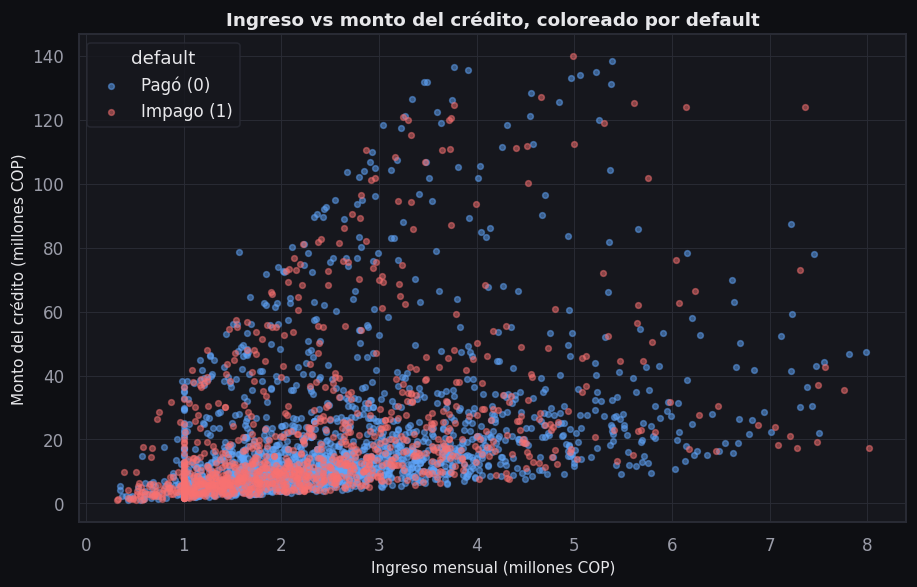

Correlación de Pearson ingreso-monto (muestra): 0.397
Mediana del monto/ingreso por clase: {'Pagó (0)': 5.0, 'Impago (1)': 5.25}


In [31]:
d = df[(df["ingreso_mensual"] <= df["ingreso_mensual"].quantile(0.99)) &
       (df["monto_credito"] <= df["monto_credito"].quantile(0.99))]
d = d.sample(min(3000, len(d)), random_state=config.RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
series = []
for clase in (0, 1):
    s = d[d[TARGET] == clase]
    x, y = s["ingreso_mensual"] / 1e6, s["monto_credito"] / 1e6
    ax.scatter(x, y, s=14, alpha=0.5, color=COLORES_CLASE[clase], label=NOMBRE_CLASE[clase])
    series.append({"nombre": NOMBRE_CLASE[clase], "puntos": np.column_stack([x, y]).round(4).tolist()})
ax.set(title="Ingreso vs monto del crédito, coloreado por default",
       xlabel="Ingreso mensual (millones COP)", ylabel="Monto del crédito (millones COP)")
ax.legend(title="default")
plt.show()
figura_front("dispersion", "Ingreso vs monto del crédito, coloreado por default", {"series": series},
             ejes={"x": "Ingreso mensual (millones COP)", "y": "Monto del crédito (millones COP)"},
             clave="dispersion_ingreso_monto", nota="Muestra aleatoria de 3.000 clientes (≤ p99)")
print(f"Correlación de Pearson ingreso-monto (muestra): {d['ingreso_mensual'].corr(d['monto_credito']):.3f}")
print("Mediana del monto/ingreso por clase:",
      (d["monto_credito"] / d["ingreso_mensual"]).groupby(d[TARGET]).median().round(2).rename(NOMBRE_CLASE).to_dict())

**Interpretación.** El monto crece con el ingreso (correlación de Pearson 0,397 en la muestra), con mucha
dispersión. Los impagos no forman una región separada en este plano: la mediana del cociente monto/ingreso es
apenas mayor en los impagos (5,25 frente a 5,0). Ingreso y monto discriminan poco por sí solos; se combinarán
en ratios (cuota/ingreso y monto/ingreso) en el paso 3.

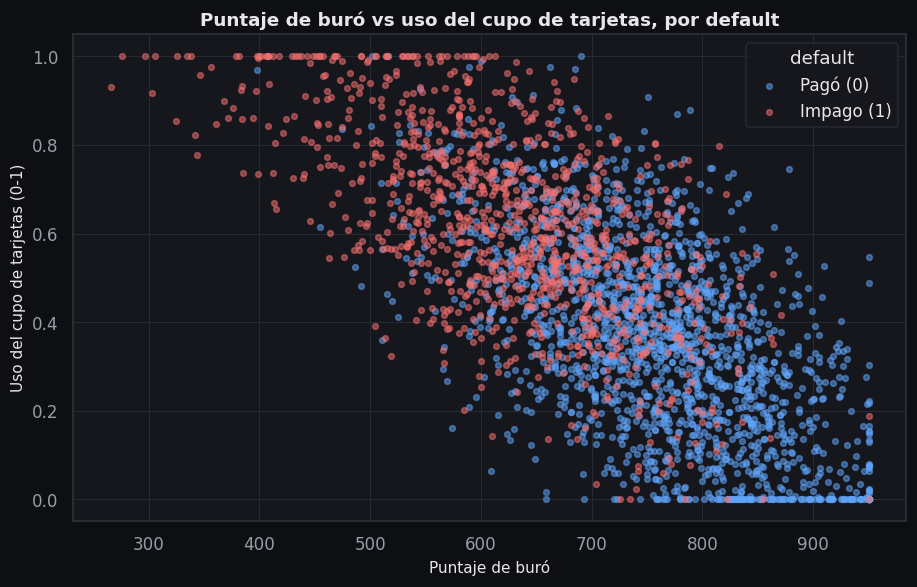

En la muestra: buró < 600 y cupo > 0,7 -> 300 clientes, impago 89.0%; resto -> impago 30.2%


In [32]:
d2 = df.dropna(subset=["puntaje_buro", "uso_cupo_tarjetas"])
d2 = d2.sample(min(3000, len(d2)), random_state=config.RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
series = []
for clase in (0, 1):
    s = d2[d2[TARGET] == clase]
    ax.scatter(s["puntaje_buro"], s["uso_cupo_tarjetas"], s=14, alpha=0.5, color=COLORES_CLASE[clase],
               label=NOMBRE_CLASE[clase])
    series.append({"nombre": NOMBRE_CLASE[clase],
                   "puntos": s[["puntaje_buro", "uso_cupo_tarjetas"]].round(4).values.tolist()})
ax.set(title="Puntaje de buró vs uso del cupo de tarjetas, por default",
       xlabel="Puntaje de buró", ylabel="Uso del cupo de tarjetas (0-1)")
ax.legend(title="default")
plt.show()
figura_front("dispersion", "Puntaje de buró vs uso del cupo de tarjetas, por default", {"series": series},
             ejes={"x": "Puntaje de buró", "y": "Uso del cupo de tarjetas (0-1)"},
             clave="dispersion_buro_cupo", nota="Muestra aleatoria de 3.000 clientes")
zona = (d2["puntaje_buro"] < 600) & (d2["uso_cupo_tarjetas"] > 0.7)
print(f"En la muestra: buró < 600 y cupo > 0,7 -> {int(zona.sum())} clientes, impago {d2.loc[zona, TARGET].mean():.1%}; "
      f"resto -> impago {d2.loc[~zona, TARGET].mean():.1%}")

**Interpretación.** Aquí sí hay separación visible: los impagos se acumulan en la zona de **buró bajo y uso
del cupo alto**, y los buenos pagadores dominan la de buró alto y uso bajo. En la muestra, los 300 clientes
con buró < 600 y cupo > 0,7 tienen un impago del 89,0 %, frente al 30,2 % del resto. Las dos variables se
complementan.

### 5.4 Boxplots por clase

Cajas = cuartiles; bigotes = último dato dentro de 1,5 × IQR (convención de Tukey); los puntos fuera de los
bigotes no se dibujan para no saturar la figura.

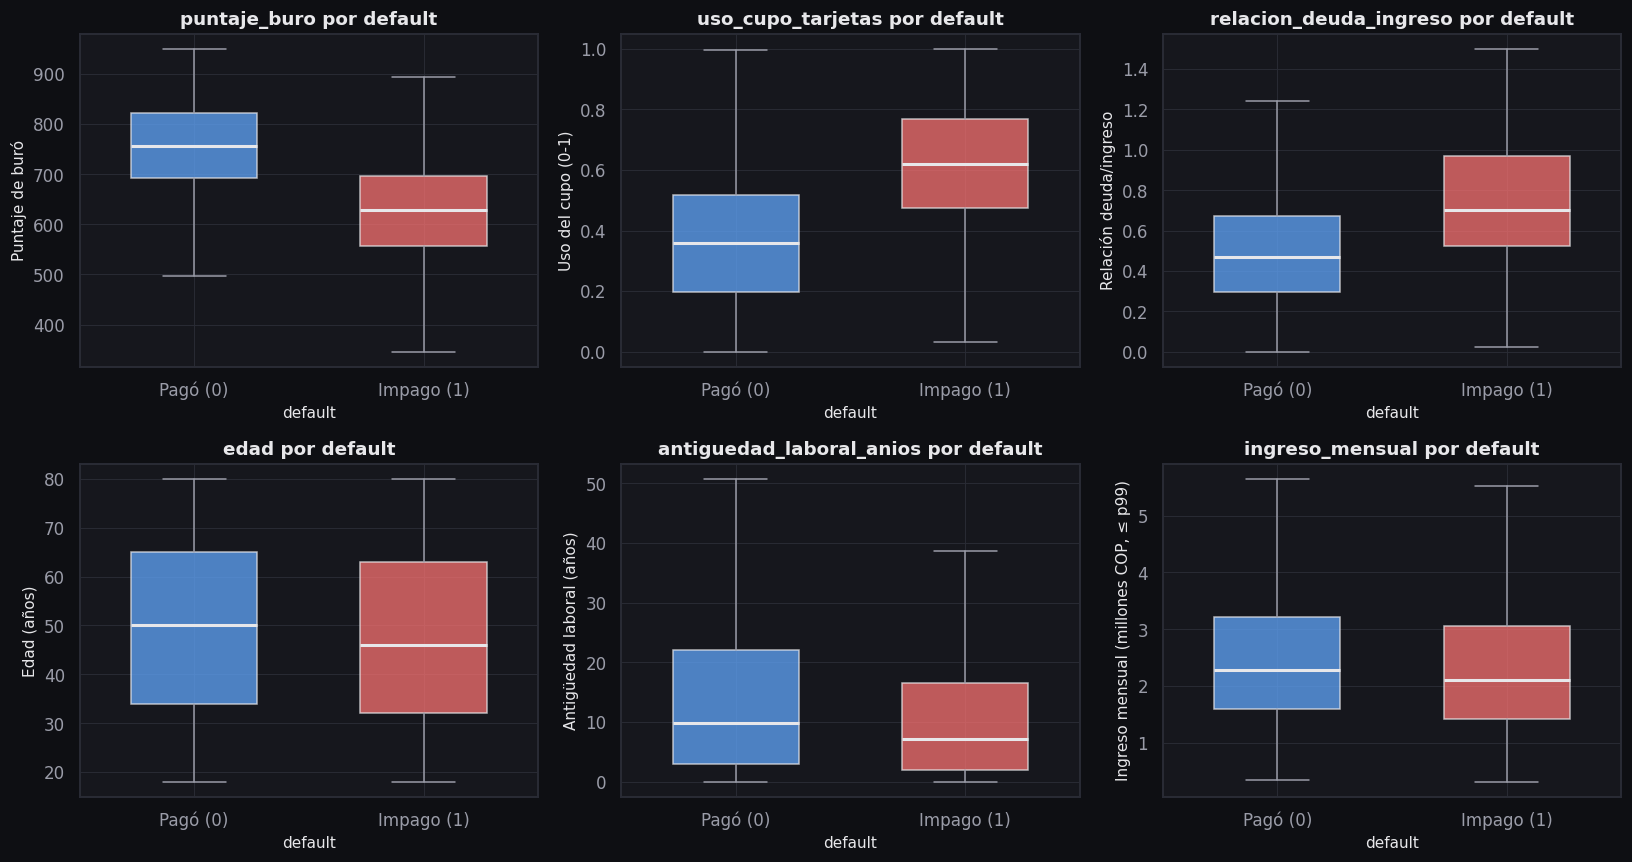

,Pagó (0),Impago (1)
mediana,,
puntaje_buro,756.00,628.00
uso_cupo_tarjetas,0.36,0.62
relacion_deuda_ingreso,0.47,0.70
edad,50.00,46.00
antiguedad_laboral_anios,9.90,7.20
ingreso_mensual,2.29,2.11


In [33]:
cols_box = [("puntaje_buro", "Puntaje de buró"), ("uso_cupo_tarjetas", "Uso del cupo (0-1)"),
            ("relacion_deuda_ingreso", "Relación deuda/ingreso"), ("edad", "Edad (años)"),
            ("antiguedad_laboral_anios", "Antigüedad laboral (años)"),
            ("ingreso_mensual", "Ingreso mensual (millones COP, ≤ p99)")]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
medianas = {}
for ax, (col, yl) in zip(axes.ravel(), cols_box):
    datos = df[[col, TARGET]].dropna()
    if col == "edad":
        datos = datos[datos["edad"].between(*config.EDAD_VALIDA)]
    if col == "ingreso_mensual":
        datos = datos[datos[col] <= datos[col].quantile(0.99)].assign(ingreso_mensual=lambda x: x[col] / 1e6)
    stats = [boxplot_stats(datos.loc[datos[TARGET] == clase, col].to_numpy())[0] for clase in (0, 1)]
    cajas = ax.bxp(stats, showfliers=False, patch_artist=True, widths=0.55,
                   whiskerprops={"color": PALETA["texto_suave"]}, capprops={"color": PALETA["texto_suave"]})
    for caja, clase in zip(cajas["boxes"], (0, 1)):
        caja.set(facecolor=COLORES_CLASE[clase], alpha=0.75, edgecolor=PALETA["texto"])
    for med in cajas["medians"]:
        med.set(color=PALETA["texto"], lw=2)
    ax.set_xticks([1, 2], [NOMBRE_CLASE[0], NOMBRE_CLASE[1]])
    ax.set(title=f"{col} por default", xlabel="default", ylabel=yl)
    medianas[col] = {NOMBRE_CLASE[c]: st["med"] for c, st in zip((0, 1), stats)}
    figura_front("boxplot", f"{col} por default",
                 {"categorias": [NOMBRE_CLASE[0], NOMBRE_CLASE[1]],
                  "series": [{"nombre": yl, "cajas": [[round(float(st[k]), 4) for k in ("whislo", "q1", "med", "q3", "whishi")]
                                                       for st in stats]}]},
                 ejes={"x": "default", "y": yl}, clave=f"box_{col}", nota="Bigotes a 1,5 × IQR (Tukey)")
plt.show()
pd.DataFrame(medianas).T.rename_axis("mediana")

**Interpretación.** Las medianas de **puntaje de buró** (756 frente a 628), **uso del cupo** (0,36 frente a
0,62) y **deuda/ingreso** (0,47 frente a 0,70) difieren claramente y sus cajas (rango intercuartílico) se
solapan poco. Los impagos son algo **más jóvenes** (mediana 46 frente a 50 años), con **menos antigüedad
laboral** (7,2 frente a 9,9 años) e **ingreso algo menor** (2,11 frente a 2,29 millones); en estas tres las
cajas se solapan mucho, por lo que su poder predictivo individual es menor. La diferencia de edad es la que
el notebook 01 marcó como riesgo de equidad.

### 5.5 Barras: tasa de impago por categoría

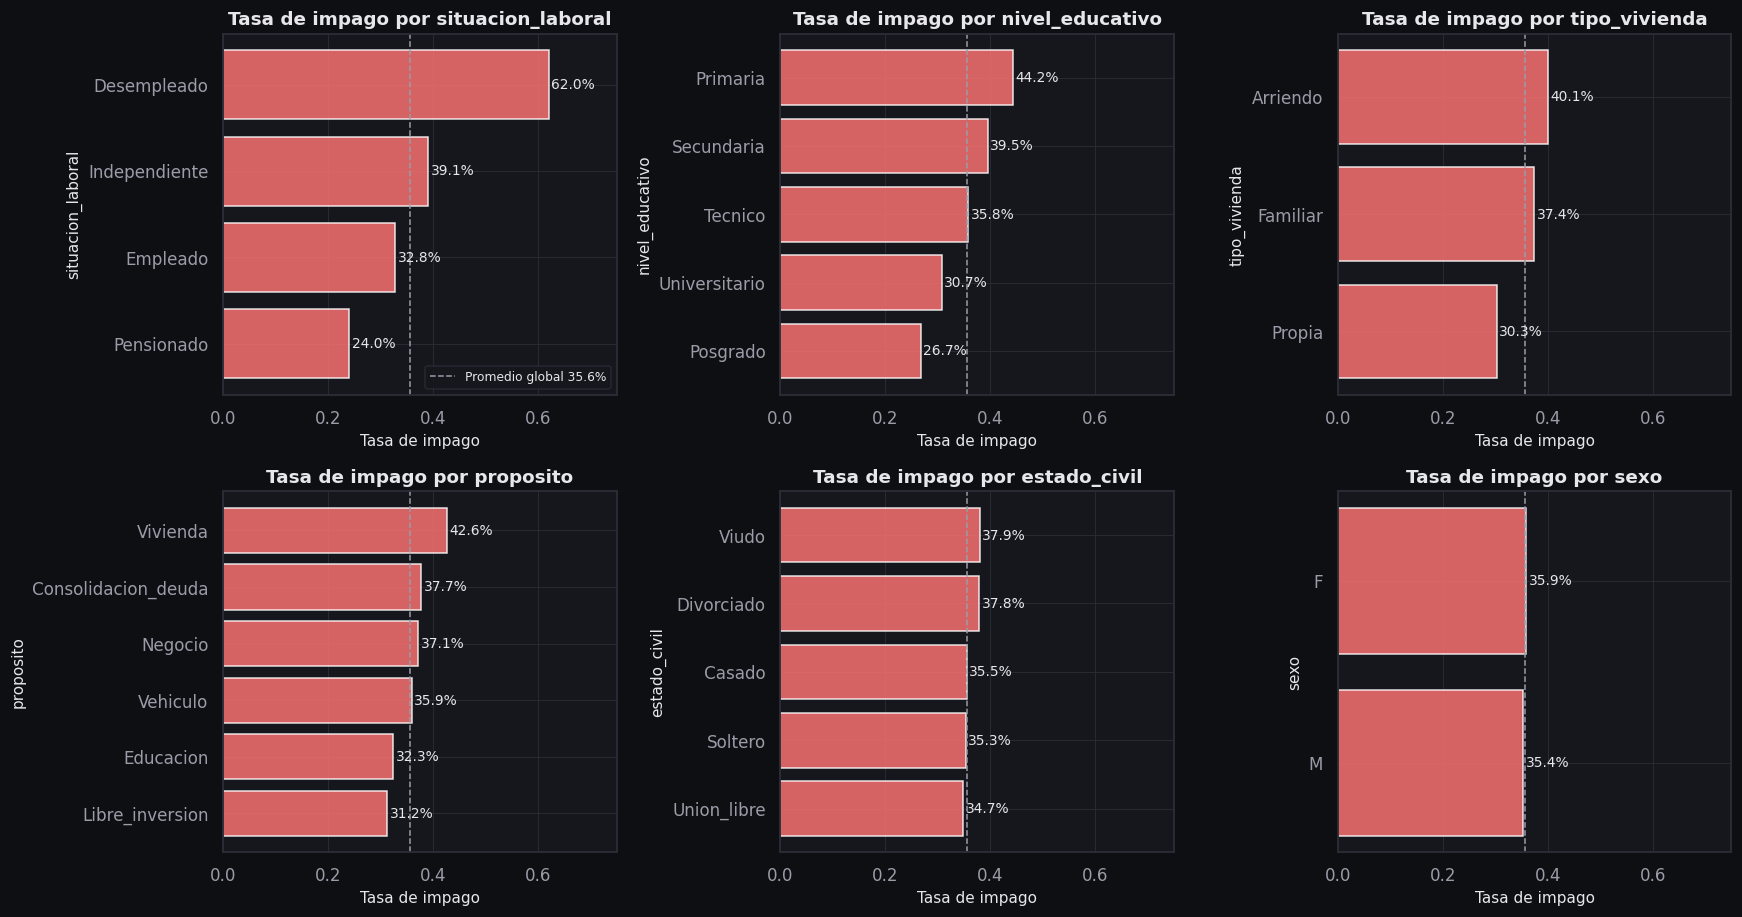

In [34]:
cats = ["situacion_laboral", "nivel_educativo", "tipo_vivienda", "proposito", "estado_civil", "sexo"]
tasa_global = df[TARGET].mean()
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
tasas_cat = {}
for ax, col in zip(axes.ravel(), cats):
    tasa = df.groupby(col)[TARGET].mean().sort_values()
    tasas_cat[col] = tasa
    ax.barh(tasa.index, tasa.values, color=PALETA["impago"], alpha=0.85)
    ax.axvline(tasa_global, ls="--", color=PALETA["texto_suave"], lw=1, label=f"Promedio global {tasa_global:.1%}")
    for i, v in enumerate(tasa.values):
        ax.text(v + 0.005, i, f"{v:.1%}", va="center", fontsize=9, color=PALETA["texto"])
    ax.set(title=f"Tasa de impago por {col}", xlabel="Tasa de impago", ylabel=col, xlim=(0, max(0.75, tasa.max() + 0.08)))
    figura_front("barras_h", f"Tasa de impago por {col}",
                 {"categorias": tasa.index.tolist(), "series": [{"nombre": "Tasa de impago", "valores": tasa.round(4).tolist()}],
                  "referencias": [{"eje": "x", "valor": round(float(tasa_global), 4), "etiqueta": "Promedio global"}]},
                 ejes={"x": "Tasa de impago", "y": col}, clave=f"impago_por_{col}", opciones={"formato_x": "pct"})
axes[0, 0].legend(loc="lower right", fontsize=8)
plt.show()

**Interpretación.** La **situación laboral** es la categórica más discriminante (desempleados 62,0 % frente
a pensionados 24,0 %). El **nivel educativo** muestra un gradiente monótono (Primaria 44,2 % → Posgrado
26,7 %), lo que respalda codificarlo como ordinal. La vivienda **propia** (30,3 %) tiene menos impago que el
arriendo (40,1 %); por propósito, **vivienda** es el más riesgoso (42,6 %) y **libre inversión** el que menos
(31,2 %). En **estado civil** (34,7 %–37,9 %) y **sexo** (F 35,9 %, M 35,4 %) las diferencias son pequeñas,
coherentes con la línea base de equidad del notebook 01; `sexo` no se usará como predictor.

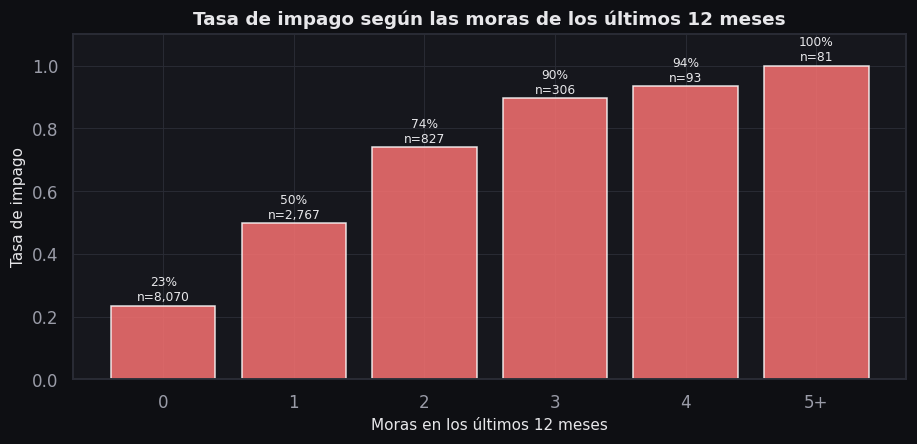

,tasa,clientes
moras_ultimos_12m,,
0,0.23,8070
1,0.50,2767
2,0.74,827
3,0.90,306
4,0.94,93
5,1.00,81


In [35]:
tasa_moras = df.groupby(df["moras_ultimos_12m"].clip(upper=5))[TARGET].agg(tasa="mean", clientes="size")
etiquetas = [str(int(i)) if i < 5 else "5+" for i in tasa_moras.index]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(etiquetas, tasa_moras["tasa"], color=PALETA["impago"], alpha=0.85)
for i, (v, n) in enumerate(tasa_moras[["tasa", "clientes"]].itertuples(index=False)):
    ax.text(i, v + 0.015, f"{v:.0%}\nn={n:,}", ha="center", fontsize=8, color=PALETA["texto"])
ax.set(title="Tasa de impago según las moras de los últimos 12 meses", xlabel="Moras en los últimos 12 meses",
       ylabel="Tasa de impago", ylim=(0, 1.1))
plt.show()
figura_front("barras", "Tasa de impago según las moras de los últimos 12 meses",
             {"categorias": etiquetas, "series": [{"nombre": "Tasa de impago", "valores": tasa_moras["tasa"].round(4).tolist()}],
              "n": tasa_moras["clientes"].astype(int).tolist()},
             ejes={"x": "Moras en los últimos 12 meses", "y": "Tasa de impago"}, clave="impago_por_moras",
             opciones={"formato_y": "pct"})
tasa_moras

**Interpretación.** El impago sube de forma monótona con las moras previas: 23 % sin moras (8.070
clientes), 50 % con una, 74 % con dos, 90 % con tres y 94 % con cuatro; los 81 clientes con cinco o más
moras incumplieron todos. El historial de pago es de los predictores más potentes, lo que justifica la
variable `tiene_moras_previas` del paso 3.

In [36]:
lab = tasas_cat["situacion_laboral"]
edu = tasas_cat["nivel_educativo"]
sx = tasas_cat["sexo"]
display(Markdown(f"""
**Resumen calculado.**

- **P1.3:** {df.shape[0]:,} filas × {df.shape[1]} columnas; tasa de default **{df[TARGET].mean():.2%}**.
  Nulos en **{len(nulos)} columnas** (máximo `{nulos.index[0]}` {nulos['pct'].iloc[0]:.1f} %, mínimo
  `{nulos.index[-1]}` {nulos['pct'].iloc[-1]:.1f} %); **{dup_exactos} filas duplicadas** exactas,
  **{dup_id} IDs repetidos** y **{int(edad_invalida.sum())} edades** fuera de {config.EDAD_VALIDA}.
- **P1.4:** las 11 operaciones dieron el mismo resultado en pandas y en DuckDB. Con moras previas el impago es
  **{f1_pd['tasa_default'].iloc[0]:.1%}**; con buró < 600 y cupo > 0,7, **{q_pd[TARGET].mean():.1%}**
  ({len(q_pd):,} clientes).
- **P1.5:** situación laboral de {lab.idxmax()} {lab.max():.1%} frente a {lab.idxmin()} {lab.min():.1%};
  educación de {edu.idxmax()} {edu.max():.1%} a {edu.idxmin()} {edu.min():.1%}; sexo
  {', '.join(f'{k} {v:.1%}' for k, v in sx.items())}. Impago con 0 moras {tasa_moras['tasa'].iloc[0]:.1%} y con
  5+ moras {tasa_moras['tasa'].iloc[-1]:.1%}.
"""))


**Resumen calculado.**

- **P1.3:** 12,144 filas × 21 columnas; tasa de default **35.63%**.
  Nulos en **7 columnas** (máximo `antiguedad_laboral_anios` 9.2 %, mínimo
  `texto_solicitud` 2.0 %); **144 filas duplicadas** exactas,
  **144 IDs repetidos** y **25 edades** fuera de (18, 100).
- **P1.4:** las 11 operaciones dieron el mismo resultado en pandas y en DuckDB. Con moras previas el impago es
  **59.7%**; con buró < 600 y cupo > 0,7, **87.7%**
  (1,177 clientes).
- **P1.5:** situación laboral de Desempleado 62.0% frente a Pensionado 24.0%;
  educación de Primaria 44.2% a Posgrado 26.7%; sexo
  M 35.4%, F 35.9%. Impago con 0 moras 23.5% y con
  5+ moras 100.0%.


## Conclusiones

- **P1.1–P1.2 (P1.E1):** el entorno queda documentado: `setup()` fija la semilla 42 y el estilo, y reporta
  Python 3.10.7, pandas 2.3.3, NumPy 1.26.4, Matplotlib 3.10.9, Seaborn 0.13.2 y DuckDB 1.5.6. La celda
  `if en_colab(): ...` deja listo el camino de Google Colab (instalar el paquete y subir el CSV si falta).
- **P1.3 (P1.E2, E3):** 12.144 filas × 21 columnas con una tasa de impago del **35,63 %**. Problemas de
  calidad que se tratan en el notebook 03: nulos en 7 columnas (hasta 9,21 % en `antiguedad_laboral_anios`),
  144 filas duplicadas exactas, 25 edades imposibles y montos o ingresos con errores de digitación (máximo de
  monto 1.033.300.000 COP).
- **P1.4 (P1.E3):** selección, filtrado, `query`, ordenamiento, `groupby`, `pivot_table` y `value_counts` se
  hicieron en pandas y en **SQL con DuckDB**, con resultados idénticos en las 11 comparaciones. Las moras
  previas (59,7 % de impago), el buró bajo con cupo alto (87,7 %) y el desempleo (62 %) elevan fuertemente el
  riesgo.
- **P1.5 (P1.E4):** 6 histogramas (edad, ingreso, monto y las 3 de buró/endeudamiento por clase) más la
  distribución del plazo, 2 diagramas de dispersión, 6 boxplots y 7 gráficos de barras de tasa de impago,
  cada uno interpretado y con sus datos exportados para el front.
- **Variables más prometedoras:** `puntaje_buro`, `uso_cupo_tarjetas`, `moras_ultimos_12m`,
  `relacion_deuda_ingreso`, `situacion_laboral` y `nivel_educativo`. Ingreso y monto discriminan poco por sí
  solos y se combinarán en ratios. `sexo` no muestra diferencias relevantes y queda fuera del modelo; la edad
  sí difiere entre clases y se vigila por equidad.